In [1]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/../utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 12+1))
# read_ids = [0, 2, 3, 8, 9]
plot_id = 0

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

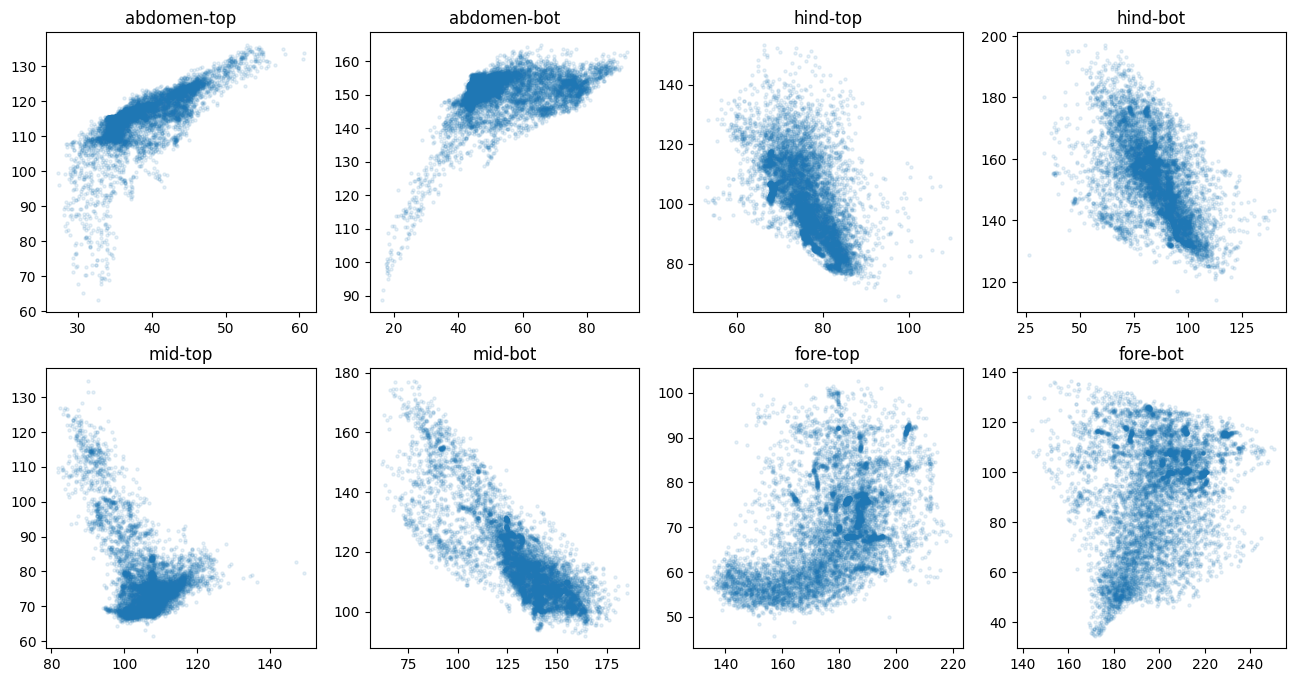

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx in range(len(markers[file_ids.index(plot_id)].columns) // 2):
	title = markers[file_ids.index(plot_id)].columns[idx * 2].split('_')[0]
	axes[idx // 4, idx % 4].set_title(title)

	axes[idx // 4, idx % 4].scatter(markers[file_ids.index(plot_id)].values[:, idx * 2],
									markers[file_ids.index(plot_id)].values[:, idx * 2 + 1],
									s=5, alpha=0.1)

In [6]:
markers_zs = [pd.DataFrame(data=StandardScaler().fit_transform(marker.values), columns=marker.columns) for marker in markers]

In [7]:
# fig, axes = plt.subplots(2, 4, figsize=(16, 8))
#
# for idx in range(len(markers_zs[file_ids.index(plot_id)].columns) // 2):
# 	title = markers_zs[file_ids.index(plot_id)].columns[idx * 2].split('_')[0]
# 	axes[idx // 4, idx % 4].set_title(title)
#
# 	axes[idx // 4, idx % 4].scatter(markers_zs[file_ids.index(plot_id)].values[:, idx * 2],
# 									markers_zs[file_ids.index(plot_id)].values[:, idx * 2 + 1],
# 									s=5, alpha=0.1)

# PCA

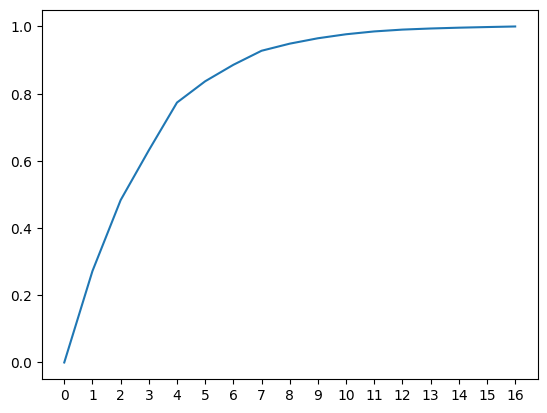

In [8]:
n_pc = 16
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)].values)
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
plt.xticks(range(16+1))
pass

In [9]:
n_pc = 8
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[file_ids.index(plot_id)])
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[file_ids.index(plot_id)].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

# plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
# plt.xticks(range(n_pc+1))
print(np.sum(vars_expl[:vars_expl.shape[0]]))

0.9488697248342737


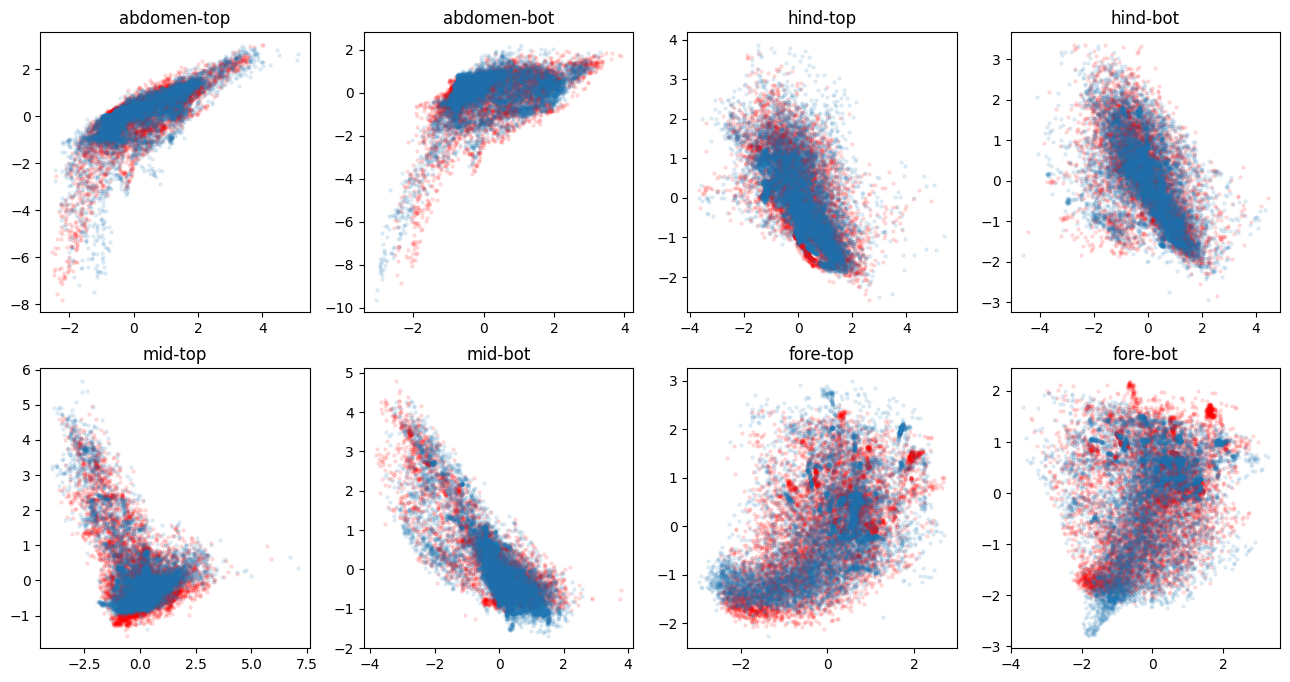

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx in range(len(recon.columns) // 2):
	title = recon.columns[idx * 2].split('_')[0]
	axes[idx // 4, idx % 4].set_title(title)

	axes[idx // 4, idx % 4].scatter(recon.values[:, idx * 2],
									recon.values[:, idx * 2 + 1],
									s=5, alpha=0.1, color='red')
	axes[idx // 4, idx % 4].scatter(markers_zs[file_ids.index(plot_id)].values[:, idx * 2],
									markers_zs[file_ids.index(plot_id)].values[:, idx * 2 + 1],
									s=5, alpha=0.1)

# motion energy

In [25]:
markers_me = [pd.DataFrame(data=marker.values[1:, :] - marker.values[:-1, :], columns=marker.columns) for marker in markers]

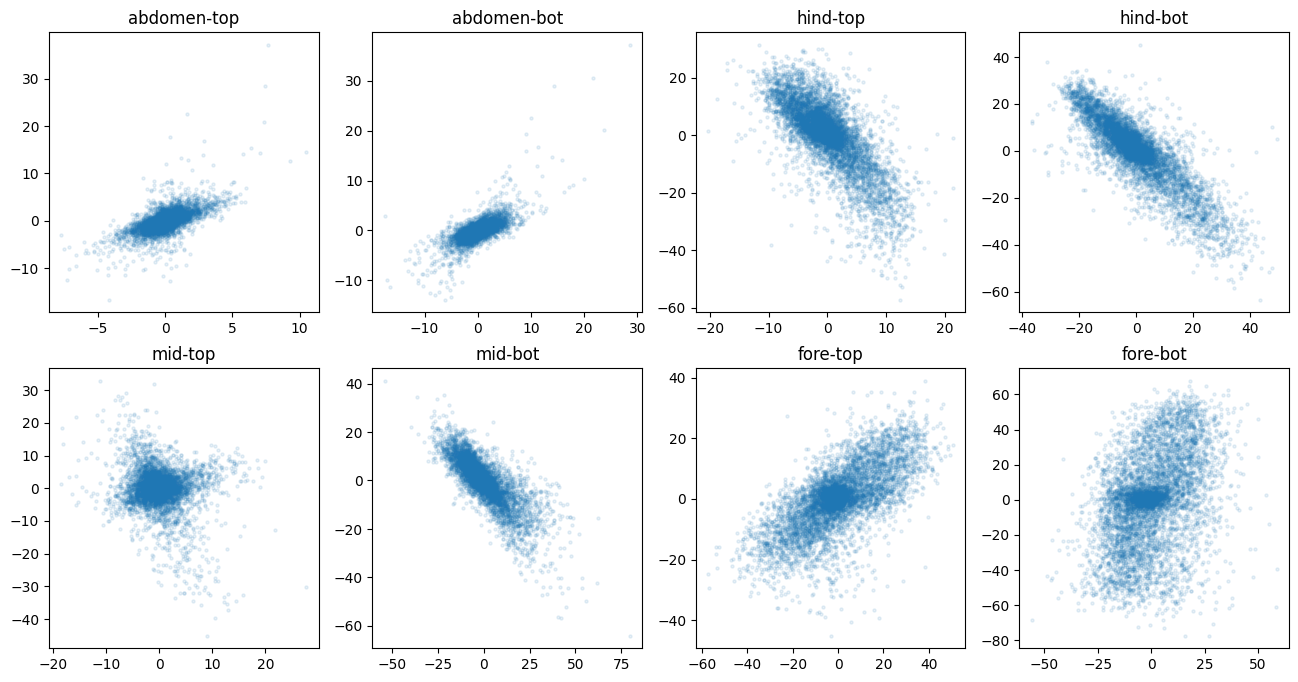

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx in range(len(markers_me[file_ids.index(plot_id)].columns) // 2):
	title = markers_me[file_ids.index(plot_id)].columns[idx * 2].split('_')[0]
	axes[idx // 4, idx % 4].set_title(title)

	axes[idx // 4, idx % 4].scatter(markers_me[file_ids.index(plot_id)].values[:, idx * 2],
									markers_me[file_ids.index(plot_id)].values[:, idx * 2 + 1],
									s=5, alpha=0.1)

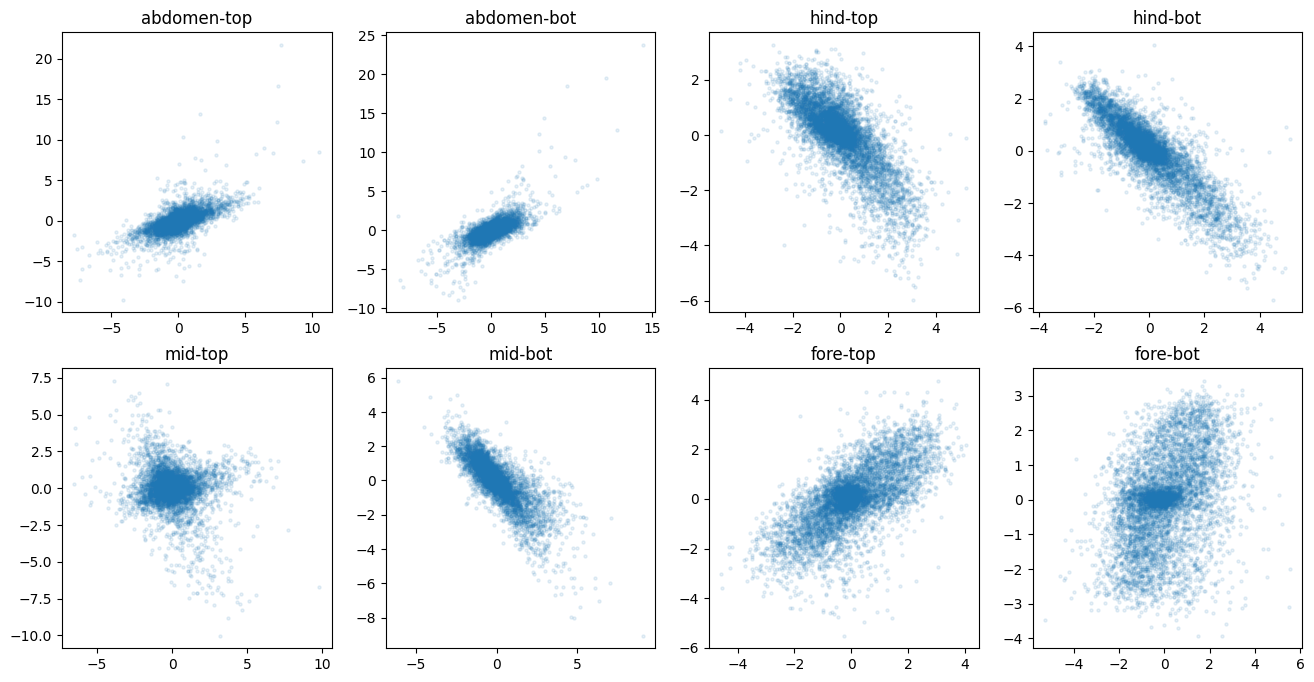

In [29]:
markers_me_zs = [
	pd.DataFrame(
		data=(marker_me.values - marker_me.values.mean(axis=0)) / np.where((marker_std := np.std(marker_me.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker_me.columns)
	for marker_me in markers_me
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx in range(len(markers_me_zs[file_ids.index(plot_id)].columns) // 2):
	title = markers_me_zs[file_ids.index(plot_id)].columns[idx * 2].split('_')[0]
	axes[idx // 4, idx % 4].set_title(title)

	axes[idx // 4, idx % 4].scatter(markers_me_zs[file_ids.index(plot_id)].values[:, idx * 2],
									markers_me_zs[file_ids.index(plot_id)].values[:, idx * 2 + 1],
									s=5, alpha=0.1)